<a href="https://colab.research.google.com/github/Shravya-7/Ai-Agent-course/blob/main/Dist_pythonlab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

In [28]:
#defining ND and generating 400 values
#create linear space
x=np.linspace(-4,4,400)
#linspace(start, stop, no.of numbers)
#generates smooth normal dist curve

In [29]:
#create ND
std_normal = stats.norm(0,1)
#mu = 0
#sigma = 1

In [30]:
#this method tells how much probability lies within one, two, and three standard deviations of mean
#verify 68-95-99.7 rule; calculate the quartiles
print('68-95-99.7:')
print(f'P(-1<Z<1) = {std_normal.cdf(1) - std_normal.cdf(-1):.6f})')
print(f'P(-2<Z<2) = {std_normal.cdf(2) - std_normal.cdf(-2):.6f})')
print(f'P(-3<Z<3) = {std_normal.cdf(3) - std_normal.cdf(-3):.6f})')

68-95-99.7:
P(-1<Z<1) = 0.682689)
P(-2<Z<2) = 0.954500)
P(-3<Z<3) = 0.997300)


In [31]:
#Z score standardization
#tells how many std deviations a value is above or below the mean
mu_exam, sigma_exam = 70, 10
for score in [60, 70, 80, 90]:
  z = (score - mu_exam) / sigma_exam
  pct = std_normal.cdf(z)*100
  print(f'Score = {score}: Z = {z:.2f}, Percentile = {pct:.1f}%')

Score = 60: Z = -1.00, Percentile = 15.9%
Score = 70: Z = 0.00, Percentile = 50.0%
Score = 80: Z = 1.00, Percentile = 84.1%
Score = 90: Z = 2.00, Percentile = 97.7%


In [32]:
#EXPONENETIAL DISTRIBUTION
lam =1.0
exp_dist = stats.expon(scale = 1/lam)
print(f'Exp(lam = 1): Mean = {exp_dist.mean()}, Var = {exp_dist.var()}')

#memoryless property
#Special property used in machine learning
print(f'P(x>2) = {1-exp_dist.cdf(2):.6f}')
print(f'P(x>3|x>1) = {(1-exp_dist.cdf(3))/(1-exp_dist.cdf(1)):.6f}')

Exp(lam = 1): Mean = 1.0, Var = 1.0
P(x>2) = 0.135335
P(x>3|x>1) = 0.135335


In [33]:
#when multilple dist on a single data since the data cannot be defined using a single dist.
#CLT is applied on sample means. these sample means tends to become normal as the sample size increases
#when the sample means are distributed it follows bell shaped curve or ND

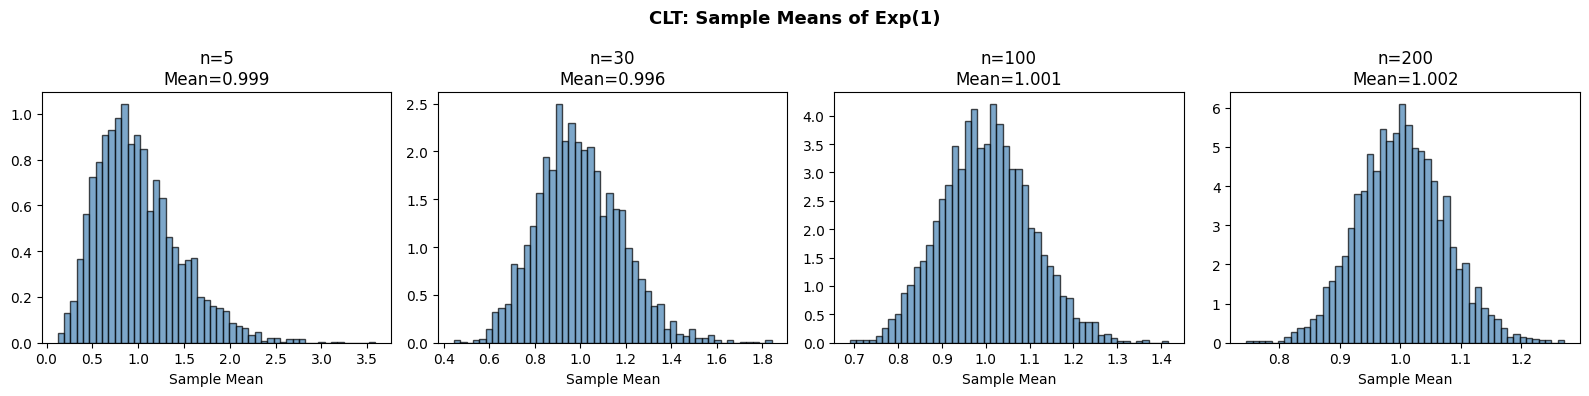

In [37]:
#Central Limit Theorem
sample_sizes = [5, 30, 100, 200]
fig, axes = plt.subplots(1, 4, figsize = (16, 4))

for i, n in enumerate(sample_sizes):
  means = [np.mean(np.random.exponential(1, n)) for _ in range(3000)]
  axes[i].hist(means, bins=50, density=True,color = 'steelblue', edgecolor = 'black', alpha = 0.7)
  axes[i].set_title(f'n={n}\nMean={np.mean(means):.3f}')
  axes[i].set_xlabel('Sample Mean')
fig.suptitle('CLT: Sample Means of Exp(1)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()